### Homework 10 part c
<br>
Filippa Mudsam

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

In [13]:
rng = np.random.default_rng()

#parameters
lam = 12
mu = 3
rho = lam/mu
T = 500
nmax = 40

In [14]:
k = np.arange(nmax+1)
pi_th = np.zeros(nmax+1)

for j in range(nmax+1):
    pi_th[j] = np.exp(-rho)*rho**j / factorial(j)

In [15]:
tstate = np.zeros(nmax+1)
t=0
n=0

while t< T:
    rate = lam + n * mu
    tau = rng.exponential(1/rate)
    if t + tau > T:
        tau = T-t
    tstate[n] += tau
    t += tau
    if rng.random() < lam / rate:
        n += 1
    else:
        n = n-1


pi_emp = tstate / T

In [16]:
maxdiff = np.max(np.abs(pi_emp - pi_th))
timeavg = np.sum(k*pi_emp)
print('largest difference |pi_emp - pi_th| =', maxdiff)
print('time average of X_t =', timeavg, '  rho =', rho)

largest difference |pi_emp - pi_th| = 0.004467599143310214
time average of X_t = 4.043215333330641   rho = 4.0


In [17]:
c = 0
while 1 - np.sum(pi_th[:c+1]) > 0.01:
    c += 1
print('smallest fleet size c =', c, '  P(X > c) =', 1 - np.sum(pi_th[:c+1]))

smallest fleet size c = 9   P(X > c) = 0.00813224279693403


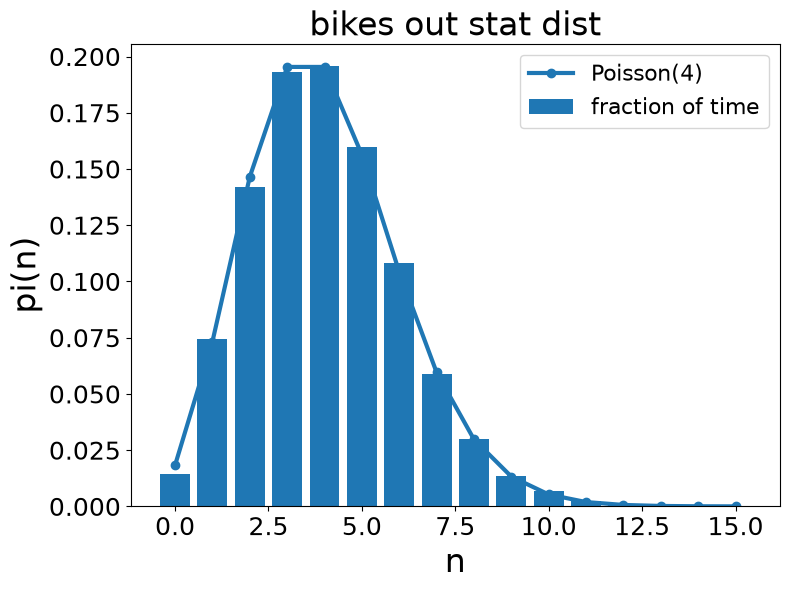

In [18]:
kplot = np.arange(16)
plt.figure(1, figsize=(8, 6))
plt.bar(kplot, pi_emp[:16], label='fraction of time')
plt.plot(kplot, pi_th[:16], '-o', linewidth=3, label='Poisson(4)')
plt.xlabel('n', fontsize=24)
plt.ylabel('pi(n)', fontsize=24)
plt.legend(loc='best', fontsize=16)
plt.title('bikes out stat dist', fontsize=24)
plt.tick_params(labelsize=18)
plt.tight_layout()
plt.show()